In [1]:
# Import necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [4]:
# =====================================================
# STEP 1: LOAD THE DATASET
# =====================================================

# 3A: Credit Card Fraud Dataset
data = pd.read_csv("ecg.csv", header=None)

# Separate features and target
X = data.iloc[:, :-1]
y = data.iloc[:, -1]

print("Dataset Shape:", data.shape)
print("\nClass Distribution:")
print(y.value_counts())


Dataset Shape: (4998, 141)

Class Distribution:
140
1.0    2919
0.0    2079
Name: count, dtype: int64


In [5]:
# =====================================================
# STEP 2: PREPROCESS THE DATA
# =====================================================

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Select only normal transactions for training
# Class 0 = Normal, Class 1 = Fraud
X_train_normal = X_train[y_train == 0]

# Scale features using only normal training transactions
scaler = StandardScaler()

X_train_normal = scaler.fit_transform(X_train_normal)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

In [6]:
# =====================================================
# STEP 3: DEFINE THE AUTOENCODER MODEL
# =====================================================

input_dim = X_train.shape[1]

# Encoder
input_layer = keras.Input(shape=(input_dim,))

encoded = layers.Dense(32, activation='relu')(input_layer)
encoded = layers.Dense(16, activation='relu')(encoded)
encoded = layers.Dense(8, activation='relu')(encoded)

# Decoder
decoded = layers.Dense(16, activation='relu')(encoded)
decoded = layers.Dense(32, activation='relu')(decoded)
decoded = layers.Dense(input_dim, activation='linear')(decoded)

# Build Autoencoder
autoencoder = keras.Model(input_layer, decoded)


In [7]:
# =====================================================
# STEP 4: COMPILE THE MODEL
# =====================================================

autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 140)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │           4,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 32)                  │             544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 140)                 │           4,620 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 10,484 (40.95 KB)

 Trainable params: 10,484 (40.95 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# =====================================================
# STEP 5: TRAIN THE AUTOENCODER
# =====================================================

history = autoencoder.fit(
    X_train_normal,
    X_train_normal,
    epochs=20,
    batch_size=256,
    validation_split=0.1,
    shuffle=True
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 12s 355ms/step - loss: 1.0089 - mae: 0.7006 - val_loss: 0.9467 - val_mae: 0.6739
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step - loss: 0.9981 - mae: 0.6972 - val_loss: 0.9362 - val_mae: 0.6707
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - loss: 0.9832 - mae: 0.6927 - val_loss: 0.9169 - val_mae: 0.6648
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step - loss: 0.9531 - mae: 0.6828 - val_loss: 0.8804 - val_mae: 0.6520
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 82ms/step - loss: 0.9009 - mae: 0.6635 - val_loss: 0.8270 - val_mae: 0.6310
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - loss: 0.8381 - mae: 0.6385 - val_loss: 0.7752 - val_mae: 0.6091
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 103ms/step - loss: 0.7839 - mae: 0.6166 - val_loss: 0.7264 - val_mae: 0.5905
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - loss: 0.7307 - mae: 0.5950 - val_loss: 0.6883 - val_mae: 0.5735
Epoch 9/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - loss: 0.6857 - mae: 0.575

In [9]:
# =====================================================
# STEP 6: CALCULATE RECONSTRUCTION ERROR
# =====================================================

# Reconstruct test data
X_pred = autoencoder.predict(X_test)

# Calculate Mean Squared Error
reconstruction_error = np.mean(
    np.square(X_test - X_pred), axis=1
)

# Set threshold using training reconstruction errors
train_pred = autoencoder.predict(X_train_normal)

train_error = np.mean(
    np.square(X_train_normal - train_pred), axis=1
)

# Threshold: 95th percentile of normal training errors
threshold = np.percentile(train_error, 95)

print("Reconstruction Error Threshold:", threshold)

# Detect anomalies
y_pred = (reconstruction_error > threshold).astype(int)

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
Reconstruction Error Threshold: 1.300650459875657


In [10]:
# =====================================================
# STEP 7: EVALUATE MODEL PERFORMANCE
# =====================================================

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))


Confusion Matrix:
[[397  19]
 [307 277]]

Classification Report:
              precision    recall  f1-score   support

         0.0       0.56      0.95      0.71       416
         1.0       0.94      0.47      0.63       584

    accuracy                           0.67      1000
   macro avg       0.75      0.71      0.67      1000
weighted avg       0.78      0.67      0.66      1000

Accuracy: 0.674
Precision: 0.9358108108108109
Recall: 0.4743150684931507
F1 Score: 0.6295454545454545


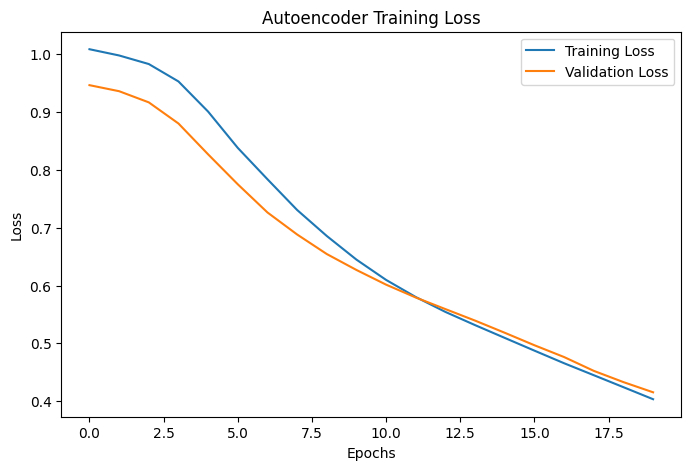

In [11]:
# =====================================================
# STEP 8: PLOT TRAINING LOSS
# =====================================================

plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

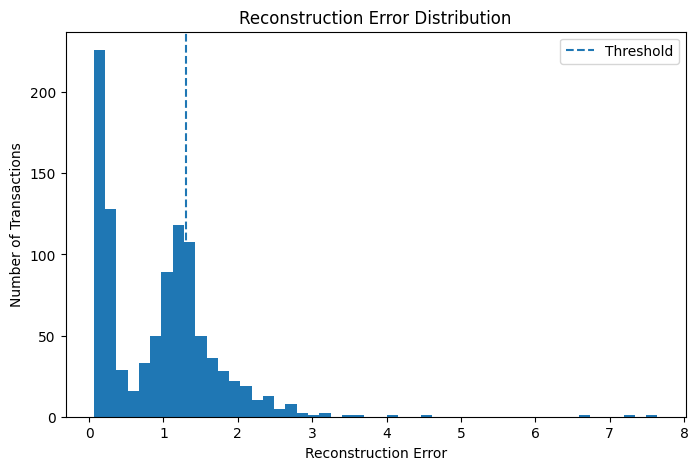

In [12]:
# =====================================================
# STEP 9: PLOT RECONSTRUCTION ERROR
# =====================================================

plt.figure(figsize=(8, 5))
plt.hist(reconstruction_error, bins=50)
plt.axvline(threshold, linestyle='--', label='Threshold')
plt.title('Reconstruction Error Distribution')
plt.xlabel('Reconstruction Error')
plt.ylabel('Number of Transactions')
plt.legend()
plt.show()